MODULE END ASSIGNMENT- STATISTICS

In [32]:
#loading and cleaning data
import numpy as np
import pandas as pd
data= pd.read_csv("/content/customer_behavior.csv")
print(data.head())
data=data.dropna()
print(data.isnull().sum())
print(data["PurchaseAmount"].value_counts())
print(data['PurchaseAmount'].mode())

   CustomerID  Gender Region  PurchaseAmount ProductCategory Churn  \
0        1001    Male  South          256.07         Fashion    No   
1        1002  Female  South             NaN     Electronics   Yes   
2        1003  Female   West         1194.41         Fashion    No   
3        1004  Female  South          413.06         Grocery    No   
4        1005    Male   West         1556.32         Fashion   Yes   

  CampaignGroup  
0             A  
1             B  
2             A  
3             A  
4             A  
CustomerID         0
Gender             0
Region             0
PurchaseAmount     0
ProductCategory    0
Churn              0
CampaignGroup      0
dtype: int64
PurchaseAmount
0.00       84
278.04      2
1944.64     2
1483.07     2
702.75      2
           ..
1568.23     1
1051.56     1
513.59      1
981.22      1
233.70      1
Name: count, Length: 3599, dtype: int64
0    0.0
Name: PurchaseAmount, dtype: float64


In [33]:
#Question 1
import statistics
mean=statistics.mean(data['PurchaseAmount'])
print("Mean of Purchase Amount is:", mean)
median=statistics.median(data['PurchaseAmount'])
print("Median of Purchase Amount is:", median)
mode=statistics.mode(data['PurchaseAmount'])
print("Mode of Purchase Amount is:", mode)

Mean of Purchase Amount is: 1001.1536716016151
Median of Purchase Amount is: 996.15
Mode of Purchase Amount is: 0.0


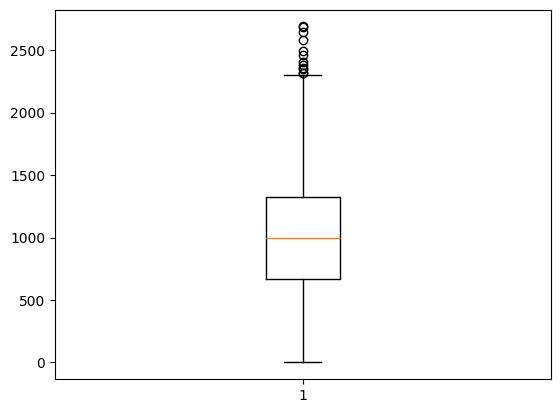

In [12]:
#Question 2: checking for outliers
import matplotlib.pyplot as plt
plt.boxplot(data['PurchaseAmount'])
plt.show()

Since there are dots beyond upper whisker, there are outliers in this column.

In [13]:
#question 3
print("Skewness:", data['PurchaseAmount'].skew())
print("Kurtosis:", data['PurchaseAmount'].kurt())

Skewness: 0.09137463187452266
Kurtosis: -0.28400835886052134


The PurchaseAmount distribution is approximately symmetric, with a very slight positive skew.The distribution has slightly lighter tails than a normal distribution.

In [34]:
#Question 4
male = data[data['Gender'] == 'Male']['PurchaseAmount']

female = data[data['Gender'] == 'Female']['PurchaseAmount']
from scipy.stats import ttest_ind

t_stat, p_value = ttest_ind(male, female, equal_var=False)

print("T-statistic:", t_stat)
print("P-value:", p_value)
if p_value < 0.05:
    print("There is a significant difference in purchase amounts between male and female customers.")
else:
    print("There is no significant difference in purchase amounts between male and female customers.")

T-statistic: 1.6528676752413163
P-value: 0.09844240203283679
There is no significant difference in purchase amounts between male and female customers.


In [35]:
#question 5
import pandas as pd

table = pd.crosstab(data['ProductCategory'], data['Churn'])

print(table)
from scipy.stats import chi2_contingency

chi2, p_value, dof, expected = chi2_contingency(table)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)
print("Expected frequencies:\n", expected)
if p_value < 0.05:
    print("There is a significant association between ProductCategory and CustomerChurn.")
else:
    print("There is no significant association between ProductCategory and CustomerChurn.")

Churn             No  Yes
ProductCategory          
Electronics      690  471
Fashion          737  533
Grocery          762  522
Chi-square statistic: 0.6359024055259498
P-value: 0.7276382942866091
Degrees of freedom: 2
Expected frequencies:
 [[684.09932705 476.90067295]
 [748.32570659 521.67429341]
 [756.57496635 527.42503365]]
There is no significant association between ProductCategory and CustomerChurn.


In [36]:
#question 6
north = data[data['Region'] == 'North']['PurchaseAmount']
south = data[data['Region'] == 'South']['PurchaseAmount']
east = data[data['Region'] == 'East']['PurchaseAmount']
west = data[data['Region'] == 'West']['PurchaseAmount']
from scipy.stats import f_oneway

f_stat, p_value = f_oneway(north, south, east, west)

print("F-statistic:", f_stat)
print("P-value:", p_value)
if p_value < 0.05:
    print("Purchase amount varies significantly across regions.")
else:
    print("There is no significant difference in purchase amount across regions.")

F-statistic: 0.6549765620050508
P-value: 0.5797709640286925
There is no significant difference in purchase amount across regions.


CampaignGroup
A    1010.275083
B     992.017516
Name: PurchaseAmount, dtype: float64


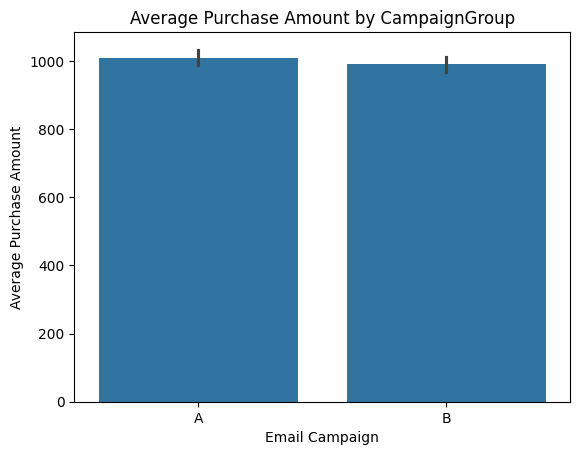

In [24]:
#question 7
print(data.groupby('CampaignGroup')['PurchaseAmount'].mean())
import seaborn as sns
import matplotlib.pyplot as plt

sns.barplot(x='CampaignGroup', y='PurchaseAmount', data=data)

plt.title("Average Purchase Amount by CampaignGroup")
plt.xlabel("Email Campaign")
plt.ylabel("Average Purchase Amount")

plt.show()

In [28]:
from scipy.stats import ttest_ind

A = data[data['CampaignGroup'] == 'A']['PurchaseAmount'].dropna()

B = data[data['CampaignGroup'] == 'B']['PurchaseAmount'].dropna()

t_stat, p_value = ttest_ind(A, B, equal_var=False)

print("T-statistic:", t_stat)
print("P-value:", p_value)
if p_value < 0.05:
    print("There is a significant difference between Campaign A and B.")
else:
    print("There is no significant difference between Campaign A and B.")
avg_A = A.mean()
avg_B = B.mean()

if avg_A > avg_B:
    print("Campaign A performed better.")
elif avg_B > avg_A:
    print("Campaign B performed better.")
else:
    print("Both campaigns have the same average purchase amount.")

T-statistic: 1.1506115509754276
P-value: 0.24996619570674117
There is no significant difference between Campaign A and B.
Campaign A performed better.


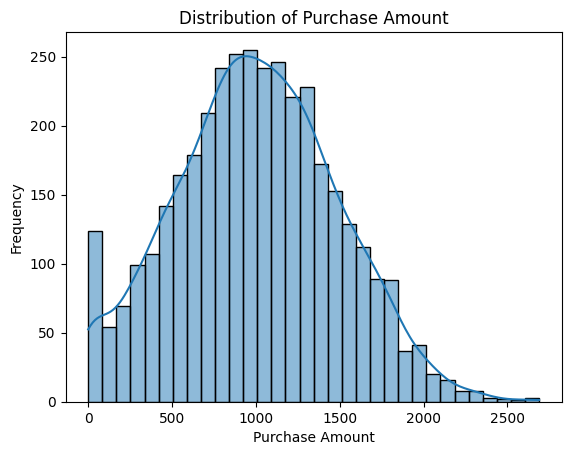

In [37]:
#question 8
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(data['PurchaseAmount'], kde=True)

plt.title("Distribution of Purchase Amount")
plt.xlabel("Purchase Amount")
plt.ylabel("Frequency")

plt.show()

It has a skewed distribution. It doesnt follow normal distribution

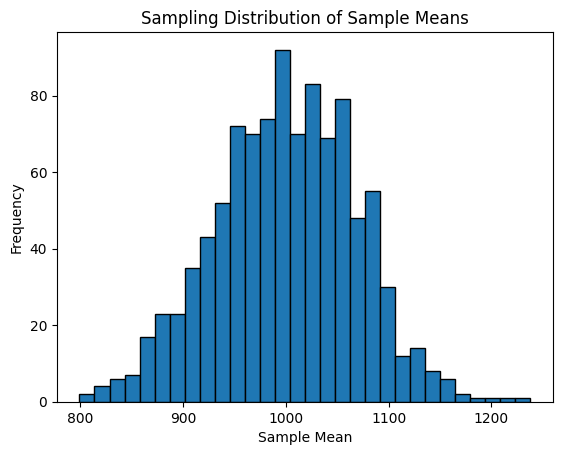

In [38]:
#question 9
import numpy as np
import matplotlib.pyplot as plt

# Remove missing values
purchase = data['PurchaseAmount'].dropna()

# Generate sample means
sample_means = []

for i in range(1000):
    sample = np.random.choice(purchase, size=50)
    sample_means.append(np.mean(sample))

# Plot sampling distribution
plt.hist(sample_means, bins=30, edgecolor='black')

plt.title("Sampling Distribution of Sample Means")
plt.xlabel("Sample Mean")
plt.ylabel("Frequency")

plt.show()

The Central Limit Theorem demonstrates that the sampling distribution of the sample mean approaches a normal distribution as the sample size increases, irrespective of the original population distribution, under appropriate conditions. By repeatedly drawing random samples from the PurchaseAmount column and calculating their means, we can observe this behaviour. This helps us estimate population parameters, construct confidence intervals and perform hypothesis testing, even when the original purchase amount distribution is not normally distributed.


In [31]:
#question 10
import numpy as np
from scipy import stats
purchase = data['PurchaseAmount'].dropna()

mean = np.mean(purchase)

ci = stats.t.interval(
    confidence=0.95,
    df=len(purchase)-1,
    loc=mean,
    scale=stats.sem(purchase)
)

print("Mean Purchase Amount:", mean)
print("95% Confidence Interval:", ci)

Mean Purchase Amount: 1001.1536716016151
95% Confidence Interval: (np.float64(985.5980578365629), np.float64(1016.7092853666672))


We are 95% confident that the true population average PurchaseAmount lies between ₹985.5980578365629 and ₹1016.7092853.